In [1]:
%load_ext autoreload
%autoreload 2

In [5]:
    
import glob, os
import pickle
import datetime
import subprocess

from collections import defaultdict

import numpy as np
import torch

from tqdm import tqdm
from ase import Atoms
from ase.io import read
from nglview import show_asetraj, show_ase

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FuncFormatter


from imlff.common.util import proj_path
from imlff.md.util import get_atoms
from imlff.data.util import load_md17_data
from imlff.data.info import md17_conformations_per_molecule, md22_conformations_per_molecule
from imlff.loading import load_model_from_wandb
from imlff.analysis.cumulene import load_or_calc, load_prep_model, style, annotate, \
    plot_E_per_atom, plot_E_per_molecule, get_indices_sel, get_Z, get_model_tag

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    
symbols = {1:'H', 6:'C'}
fig_path = proj_path('figures/')

# Compute and Save

In [3]:
def atoms_to_distances(atoms):
    R = atoms.positions
    D = np.linalg.norm(R[None] - R[:, None], axis=2, ord=2)
    mask = np.tril(np.ones((len(R), len(R)), dtype=bool), k=-1)
    return D[mask]

In [ ]:



conformations_per_molecule = dict(
    **md17_conformations_per_molecule,
    **md22_conformations_per_molecule
)

seed = 0
n_draws = 10_000

dynamic_distances = defaultdict(list)
elements_per_molecule = dict()

def save_elements_per_molecule(molecule_name, atoms):
    if molecule_name not in elements_per_molecule:
        elements_per_molecule[molecule_name] = atoms.get_chemical_symbols()

for molecule_name, n_conformations in conformations_per_molecule.items():
    np.random.seed(seed)
    try:
        i=-1
        for i in tqdm(range(n_draws)):
            molecule_idx = np.random.randint(1, n_conformations)
            # print(molecule_name, molecule_idx, n_conformations)
            atoms = get_atoms(molecule_name, molecule_idx)
            
            D = atoms_to_distances(atoms)
            dynamic_distances[molecule_name].append(D)
            
            save_elements_per_molecule(molecule_name, atoms)
    except:
        print(molecule_name, 'failed at sample', i)
        pass

  0%|          | 0/10000 [00:00<?, ?it/s]

double-walled_nanotube failed at sample 0


In [ ]:
equi_distances = defaultdict(list)

for molecule_name in conformations_per_molecule:
    pat = proj_path('results', molecule_name, verbose=False)
    files = glob.glob(f"{pat}_*/**/relaxed_kcal_mol.xyz", recursive=True)
    print(molecule_name, len(files))
    
    for f in files:
        atoms = read(f)

        R = atoms.positions
        D = np.linalg.norm(R[None] - R[:, None], axis=2, ord=2)
        mask = np.tril(np.ones((len(R), len(R)), dtype=bool), k=-1)
        equi_distances[molecule_name].append(D[mask])
        
        save_elements_per_molecule(molecule_name, atoms)

len(equi_distances)

aspirin 12
azobenzene 14
benzene 14
ethanol 18
malonaldehyde 11
naphthalene 7
paracetamol 8
salicylic_acid 10
toluene 5
uracil 6
Ac-Ala3-NHMe 33
DHA 6
stachyose 8
AT-AT 4
AT-AT-CG-CG 3
buckyball-catcher 4
double-walled_nanotube 0


16

In [ ]:
# Minimal covalent radii table (Å). Extend if you have other elements.
RCOV = {
    'H':0.31,'C':0.76,'N':0.71,'O':0.66,'F':0.57,
    'S':1.05,'Cl':1.02,'Br':1.20,'I':1.39
}

def median_mad(x):
    m = np.median(x)
    return m, 1.4826 * np.median(np.abs(x - m))

def element_pair_max_distance(ei, ej, slack=1.20):
    Ri, Rj = RCOV[ei], RCOV[ej]
    return slack * (Ri + Rj)

def default_pairs(num_pairs):
    num_atoms = lambda b: (1 + np.sqrt(1+8*b)) / 2
    a = num_atoms(num_pairs)
    
    assert a==int(a) and a>0, f"{num_pairs=} {a=}"
    a=int(a)

    mask = np.tril(np.ones((a, a), dtype=bool), k=-1)
    JJ = np.arange(a)[None].repeat(a, axis=0)
    II = JJ.T
    # JJ = II.T
    
    pairs_in_molecule = list(zip(II[mask].tolist(), JJ[mask].tolist()))
    return pairs_in_molecule

def filter_bonds_and_stats(
    equi_distances, dynamic_distances,  # dict[mol] -> list of arrays (T_i, n_pairs) of distances
    elements_per_molecule,              # dict[mol] -> list of element symbols, len = n_atoms
    pairs_per_molecule=None,            # dict[mol] -> list of (i,j) pairs, len = n_pairs, aligns with distance columns
    slack=1.20,
    min_close_frames=5
):
    """
    Returns:
      bond_catalog[mol] = {
         'bond_columns': [j, ...],
         'stats': { j: {'r0':..., 'sigma':..., 'r_min':..., 'r_max':..., 'rmax_cutoff':...} }
      }
    """
    catalog = {}
    for mol in (set(equi_distances) | set(dynamic_distances)):
        eq = equi_distances.get(mol, [])
        dy = dynamic_distances.get(mol, [])
        if not eq and not dy:
            catalog[mol] = {'pairs': [], 'stats': {}}
            continue
        
        if pairs_per_molecule is not None:
            pairs = pairs_per_molecule[mol]
            num_pairs = len(pairs)
        else:
            num_pairs = len(eq[0]) if eq else len(dy[0])
            pairs = default_pairs(num_pairs)

        # Stack frames (can be ragged lengths; assume all arrays per mol have same n_pairs)
        Xeq = np.array(eq, dtype=float) if eq else np.empty((0, num_pairs), float)
        Xdy = np.array(dy, dtype=float) if dy else np.empty((0, num_pairs), float)
        Xall = np.vstack([Xeq, Xdy]) if Xdy.size else Xeq
        Z = elements_per_molecule[mol]

        stats = {}
        bond_is = []
        bonds = []
        r0s = []
        sigmas = []

        for j, (a, b) in enumerate(pairs):
            ei, ej = Z[a], Z[b]
            if ei not in RCOV or ej not in RCOV:
                print(f"Skipping unknown element pair: {ei}-{ej}")
                continue
            rmax = element_pair_max_distance(ei, ej, slack=slack)

            col_all = Xall[:, j]
            # Quick reject: if it never gets close enough, it's not a bond
            if not np.any(col_all <= rmax):
                continue

            # Close-state samples only
            close_mask = col_all <= rmax
            r_in = col_all[close_mask]
            if r_in.size < min_close_frames:
                continue
            

            r0, sigma = median_mad(r_in)
            r0, sigma = float(r0), float(sigma)    
            stats[(a,b)] = {
                'r0': r0,
                'sigma': sigma,
                'r_min': float(r_in.min()),
                'r_max': float(r_in.max()),
                'rmax_cutoff': float(rmax),
                'n_close': int(r_in.size),
                'n_total': int(col_all.size),
                'idx_i': a,
                'idx_j': b,
                'e_i': ei,
                'e_j': ej,
                'pair_i': j,
            }
            bond_is.append(j)
            r0s.append(r0)
            sigmas.append(sigma)
            bonds.append((a, b))
        catalog[mol] = {'bond_is': bond_is, 'bonds': bonds, 'r0s': r0s, 'sigmas': sigmas, 'stats': stats}
    return catalog


In [33]:
bonds_and_stats_per_molecule = filter_bonds_and_stats(
    equi_distances, dynamic_distances,  # dict[mol] -> list of arrays (T_i, n_pairs) of distances
    elements_per_molecule,              # dict[mol] -> list of element symbols, len = n_atoms
    pairs_per_molecule=None,            # dict[mol] -> list of (i,j) pairs, len = n_pairs, aligns with distance columns
    slack=1.20,
    min_close_frames=5,
)

bonds_and_stats_per_molecule['aspirin'].keys()

dict_keys(['bond_is', 'bonds', 'r0s', 'sigmas', 'stats'])

In [34]:
for molecule, bonds_and_stats in bonds_and_stats_per_molecule.items():
    print(f"{molecule}: {len(bonds_and_stats['stats'])} bonds found")
    for (a,b), s in bonds_and_stats['stats'].items():
        if s['n_close']/s['n_total'] < .99 or 0:
            print(
                f"  {a}-{b} ({s['e_i']}-{s['e_j']}): r0={s['r0']:.3f}±{s['sigma']:.3f}Å, "
                f"rmin={s['r_min']:.3f}Å, rmax={s['r_max']:.3f}Å, "
                f"n_close={s['n_close']}/{s['n_total']} frames"
                )

aspirin: 21 bonds found
AT-AT-CG-CG: 122 bonds found
ethanol: 8 bonds found
uracil: 12 bonds found
benzene: 12 bonds found
buckyball-catcher: 194 bonds found
Ac-Ala3-NHMe: 41 bonds found
azobenzene: 25 bonds found
naphthalene: 19 bonds found
DHA: 55 bonds found
AT-AT: 63 bonds found
  24-0 (H-N): r0=1.165±0.060Å, rmin=1.123Å, rmax=1.224Å, n_close=6/10004 frames
salicylic_acid: 16 bonds found
stachyose: 90 bonds found
paracetamol: 20 bonds found
toluene: 15 bonds found
malonaldehyde: 8 bonds found


In [ ]:
# add date and commit:
git_dir = proj_path('.git')
commit_hash = subprocess.check_output(['git', '--git-dir', git_dir, 'rev-parse', '--short', 'HEAD']).strip().decode()
today_str = datetime.date.today().isoformat()

bonds_and_stats_per_molecule['metadata'] = dict(date=today_str, commit=commit_hash)

stats_path = proj_path('data', "bonds_and_stats.pkl")
with open(stats_path, "wb") as f:
    pickle.dump(bonds_and_stats_per_molecule, f)

bonds_and_stats_per_molecule.keys(), bonds_and_stats_per_molecule['metadata']

Note: /temp-in-container does not exist. Not using tmp.


(dict_keys(['aspirin', 'AT-AT-CG-CG', 'ethanol', 'uracil', 'benzene', 'buckyball-catcher', 'Ac-Ala3-NHMe', 'azobenzene', 'naphthalene', 'DHA', 'AT-AT', 'salicylic_acid', 'stachyose', 'paracetamol', 'toluene', 'malonaldehyde', 'metadata']),
 {'date': '2025-09-15', 'commit': '822844db'})

# Visualize

(1000, 210) (1000, 210)
(12, 210) (12, 210)


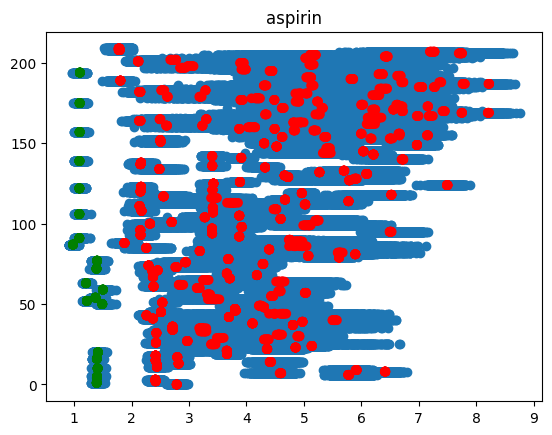

(1000, 6903) (1000, 6903)
(3, 6903) (3, 6903)


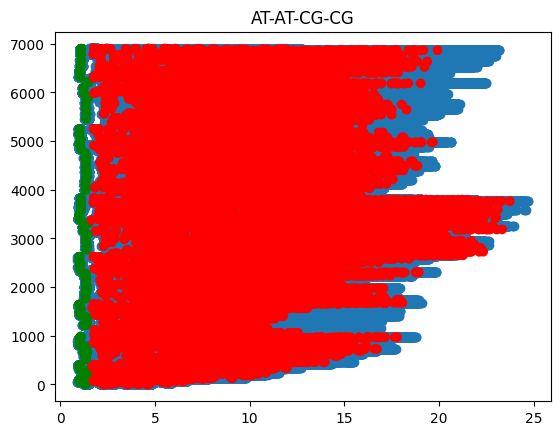

(1000, 36) (1000, 36)
(18, 36) (18, 36)


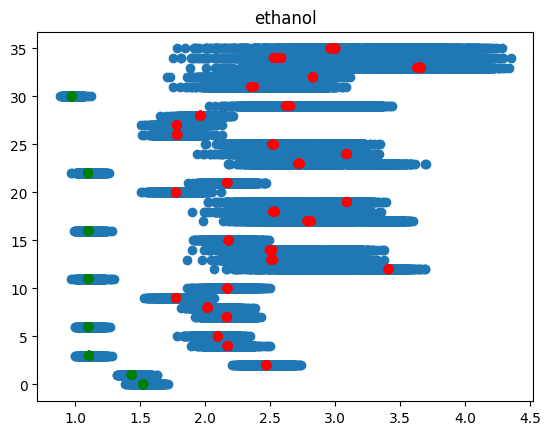

(1000, 66) (1000, 66)
(6, 66) (6, 66)


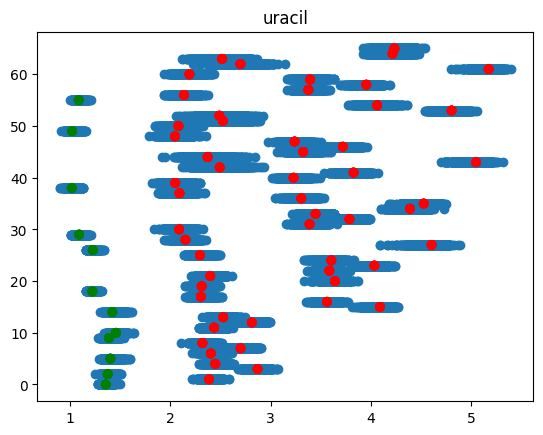

(1000, 66) (1000, 66)
(14, 66) (14, 66)


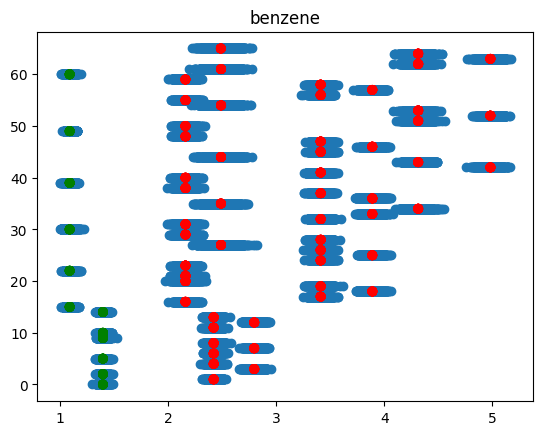

(1000, 10878) (1000, 10878)
(4, 10878) (4, 10878)


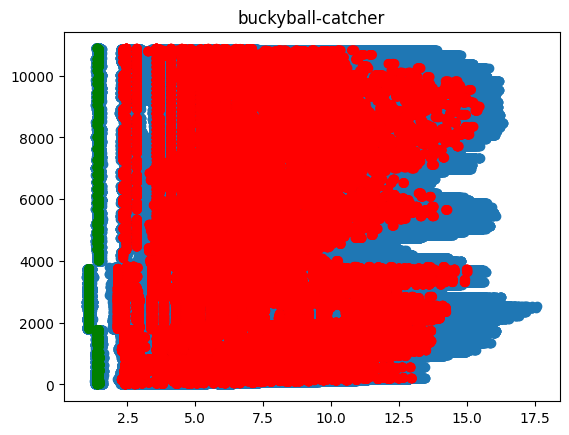

(1000, 861) (1000, 861)
(33, 861) (33, 861)


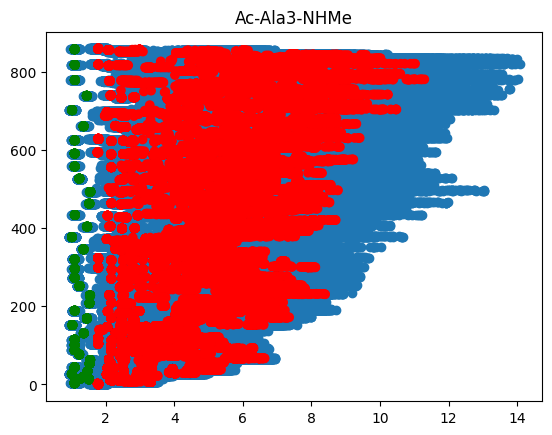

(1000, 276) (1000, 276)
(14, 276) (14, 276)


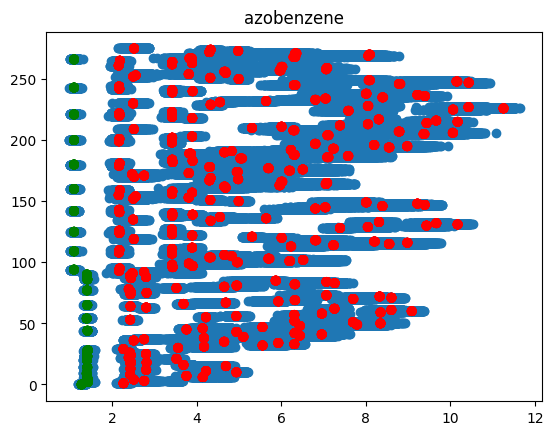

(1000, 153) (1000, 153)
(7, 153) (7, 153)


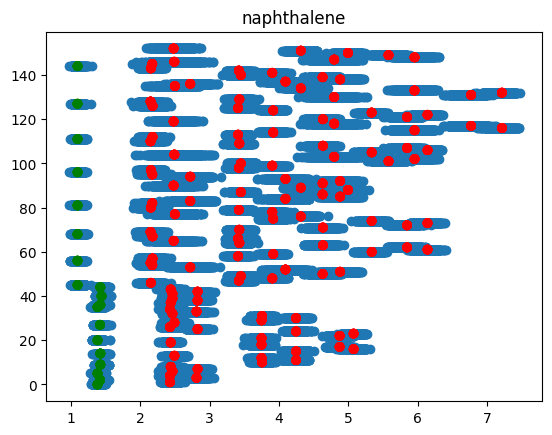

(1000, 1540) (1000, 1540)
(6, 1540) (6, 1540)


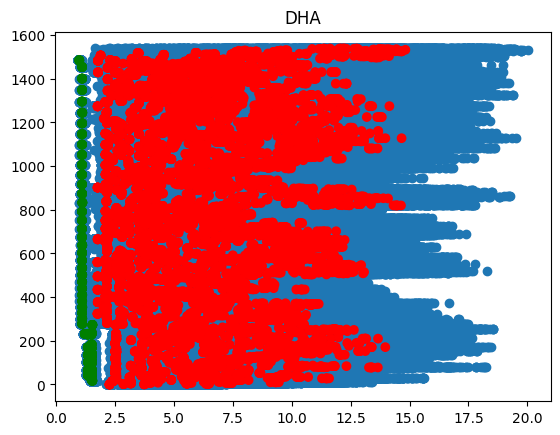

(1000, 1770) (1000, 1770)
(4, 1770) (4, 1770)


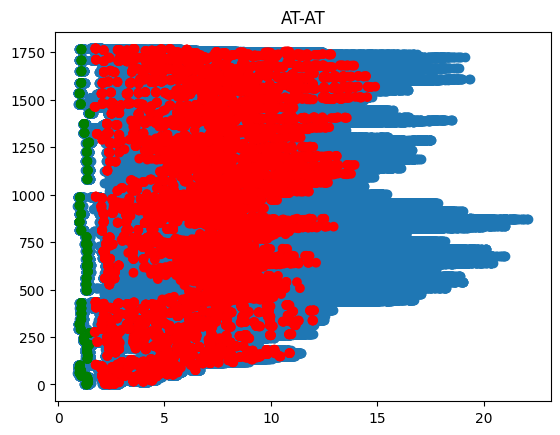

(1000, 120) (1000, 120)
(10, 120) (10, 120)


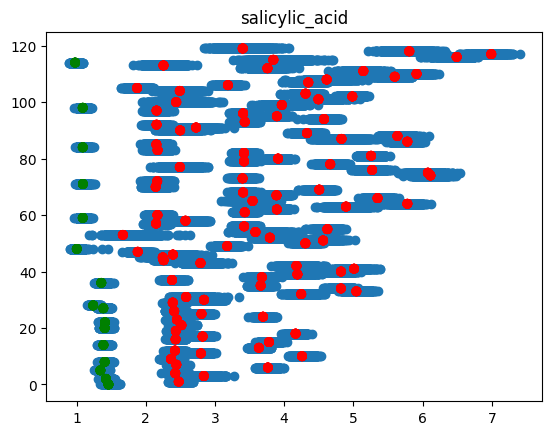

(1000, 3741) (1000, 3741)
(8, 3741) (8, 3741)


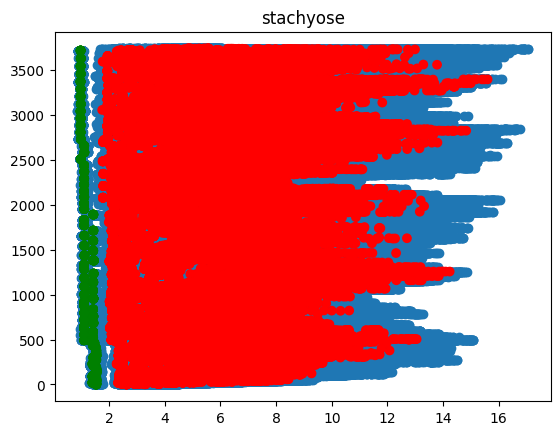

(1000, 190) (1000, 190)
(8, 190) (8, 190)


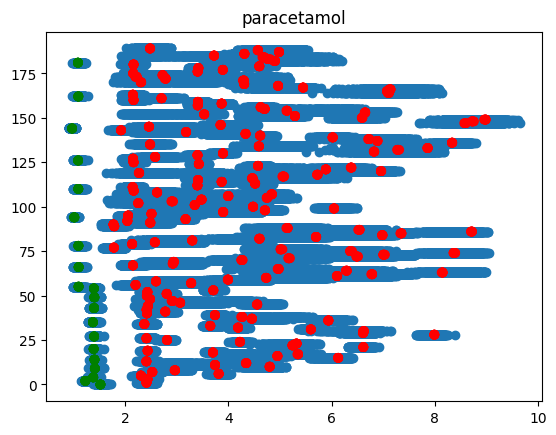

(1000, 105) (1000, 105)
(5, 105) (5, 105)


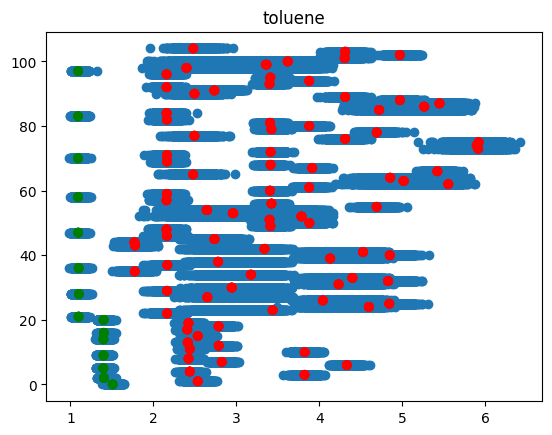

(1000, 36) (1000, 36)
(11, 36) (11, 36)


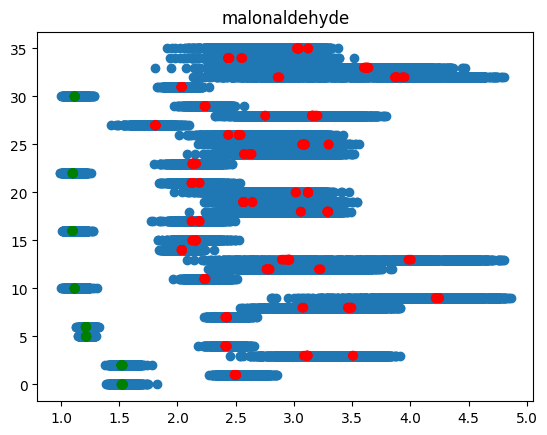

In [ ]:
for molecule_name in bonds_and_stats_per_molecule:
    bond_is = bonds_and_stats_per_molecule[molecule_name]['bond_is']
    pairs = bonds_and_stats_per_molecule[molecule_name]['pairs']
    stats = bonds_and_stats_per_molecule[molecule_name]['stats']
    for i, distances_dict in enumerate((dynamic_distances, equi_distances)):
        distances = distances_dict.get(molecule_name, [[]])
        x=np.array(distances)
        m,n = x.shape
        y=np.arange(n)
        colors = np.array(['green' if i in bond_is else 'red' for i in range(n)])
        y_repeated=y[None].repeat(m, axis=0)
        colors_repeated = colors[None].repeat(m, axis=0)

        print(x.shape, y_repeated.shape)
        # print(x)
        # print(y)
        plt.scatter(x=x.flatten(), y=y_repeated.flatten(), color=colors_repeated.flatten() if i==1 else None)
        
    plt.title(molecule_name)
    plt.show()


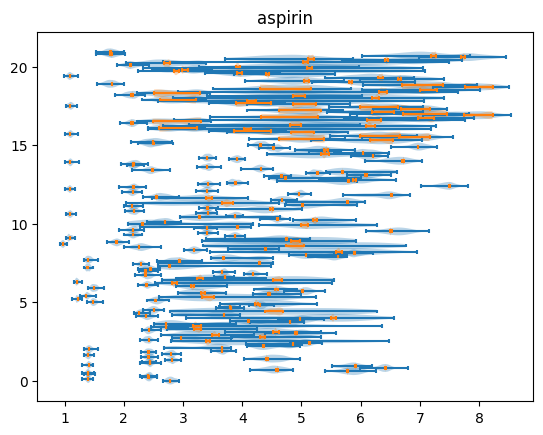

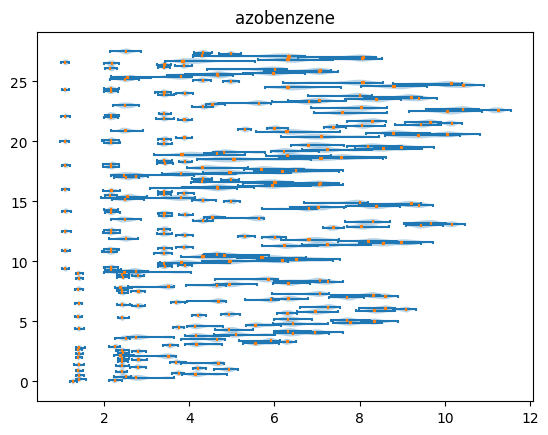

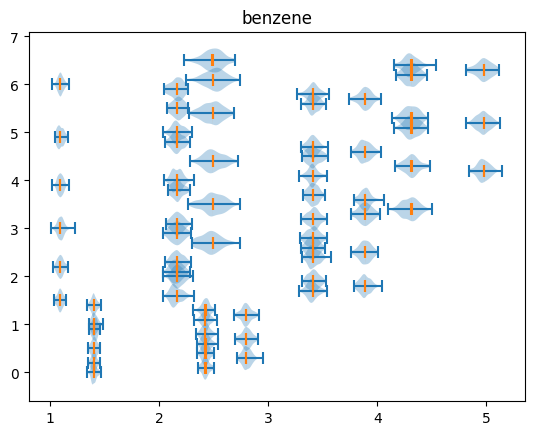

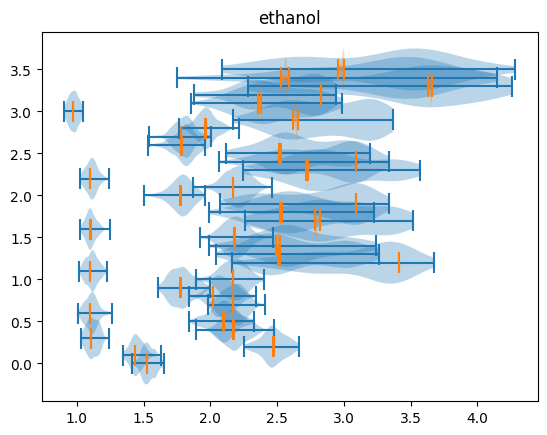

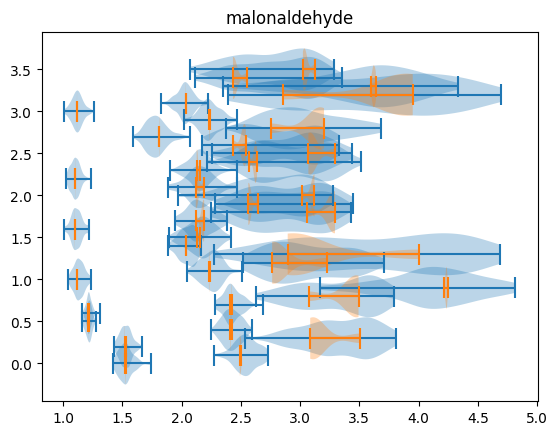

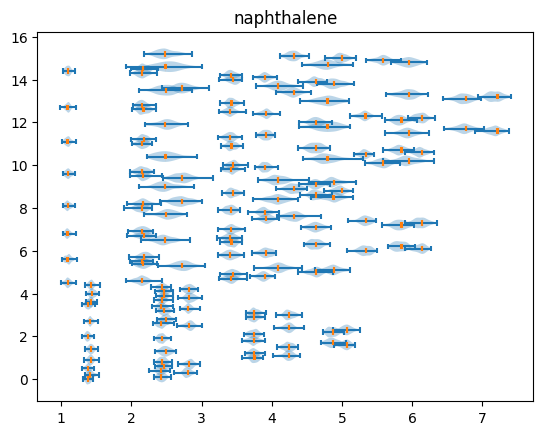

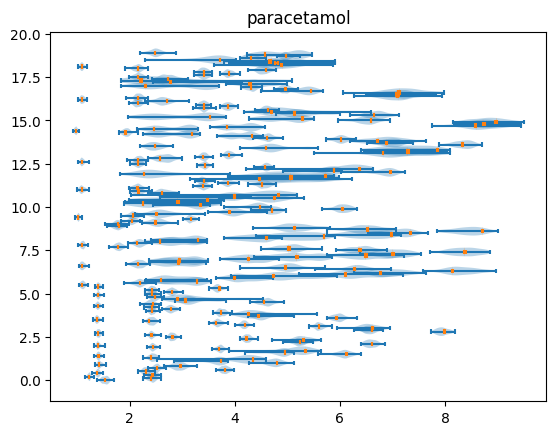

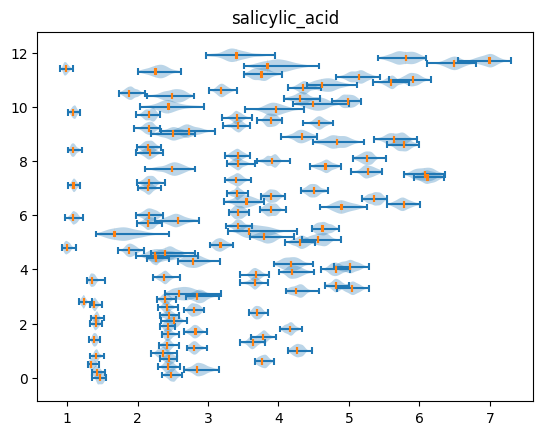

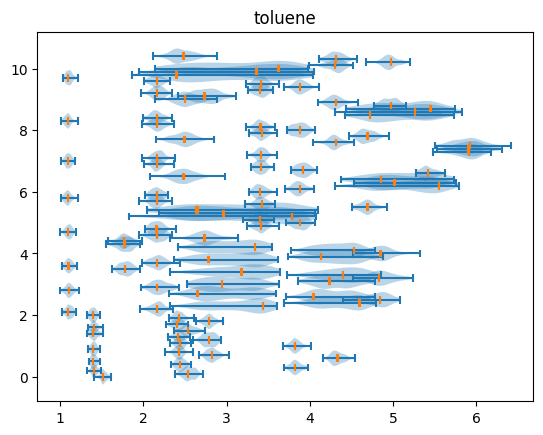

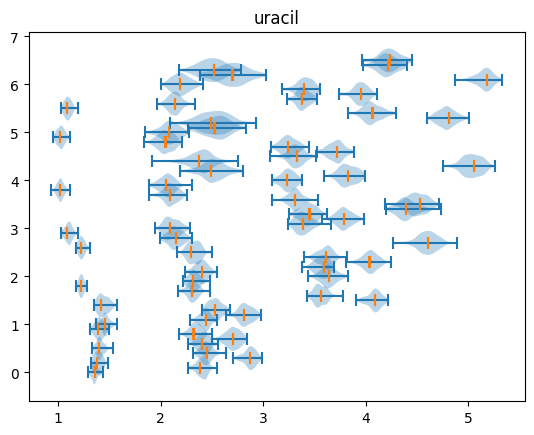

In [ ]:

for molecule_name in conformations_per_molecule:
    for distances_dict in (dynamic_distances, equi_distances):
        distances = distances_dict.get(molecule_name, [[]])
        x=np.array(distances)
        if x.size:
            m,n = x.shape
            y=np.arange(n)
            plt.violinplot(x, y/10, vert=False)
        
    plt.title(molecule_name)
    plt.show()


# Load

In [6]:
# load:
stats_path = proj_path('data', "bonds_and_stats.pkl")
with open(stats_path, "rb") as f:
    bonds_and_stats_per_molecule = pickle.load(f)

bonds_and_stats_per_molecule.keys(), bonds_and_stats_per_molecule['metadata']

Note: /temp-in-container does not exist. Not using tmp.


(dict_keys(['aspirin', 'AT-AT-CG-CG', 'ethanol', 'uracil', 'benzene', 'buckyball-catcher', 'Ac-Ala3-NHMe', 'azobenzene', 'naphthalene', 'DHA', 'AT-AT', 'salicylic_acid', 'stachyose', 'paracetamol', 'toluene', 'malonaldehyde', 'metadata']),
 {'date': '2025-09-15', 'commit': '822844db'})